Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 03. Eventos discretos. Cola de atención

Las visitas del notebook 02 no siempre se convierten en ventas. Si el mostrador está ocupado, los clientes esperan en cola y algunos se van sin comprar. Esa dinámica ocurre minuto a minuto, por lo que se modela con simulación de eventos discretos en SimPy.

En el modelo los clientes llegan según un proceso de Poisson cuya tasa cambia cada hora. Quien encuentra 6 o más personas en cola se va sin entrar, y quien entra se va si su paciencia se agota antes de ser atendido.

## 1. Parámetros de la atención

Los valores de `QueueParams` son supuestos para una cafetería abierta de 7:00 a 19:00.

In [1]:
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.append("../src")
from business_sim.finance import demand_curve
from business_sim.params import BusinessParams, QueueParams
from business_sim.queue_des import hourly_rates, loss_fraction, loss_table, mmc_wait, simulate_day, simulate_queue

p = BusinessParams()
qp = QueueParams()
pd.Series(vars(qp)).to_frame("Valor")

,Valor
servers,2
hourly_profile,"(1.6, 2.0, 1.3, 0.8, 0.9, 1.5, 1.4, 0.7, 0.6, ..."
days_per_month,30
service_mean,5.0
patience_mean,5.0
max_queue,6


Cada persona en mostrador atiende en promedio en 5 minutos, por lo que 2 servidores atienden hasta 24 clientes por hora. La hora de 8:00 concentra el doble de llegadas que una hora promedio.

## 2. Verificación contra la teoría M/M/c

Sin paciencia limitada, sin límite de cola y con tasa constante, el modelo es una fila M/M/c. Su espera promedio en cola tiene fórmula exacta (Erlang C). Se simulan 30 réplicas de 200 horas para tres configuraciones y se construye un intervalo de confianza del 95 %.

In [2]:
rng = np.random.default_rng(3)
filas = []
for lam_h, c in [(9, 1), (15, 2), (27, 3)]:
    esperas = [simulate_queue([lam_h] * 200, c, qp.service_mean, math.inf, math.inf, rng)["mean_wait"] for _ in range(30)]
    media = np.mean(esperas)
    h = stats.t.ppf(0.975, len(esperas) - 1) * stats.sem(esperas)
    teoria = mmc_wait(lam_h / 60, 1 / qp.service_mean, c)
    filas.append({
        "Llegadas por hora": lam_h, "Servidores": c, "rho": lam_h / 60 * qp.service_mean / c,
        "Wq teoría (min)": teoria, "Wq simulada (min)": media,
        "IC95 inf": media - h, "IC95 sup": media + h, "Dentro": abs(media - teoria) <= h,
    })
pd.DataFrame(filas).round(3)

,Llegadas por hora,Servidores,rho,Wq teoría (min),Wq simulada (min),IC95 inf,IC95 sup,Dentro
0,9,1,0.750,15.000,14.628,13.382,15.874,True
1,15,2,0.625,3.205,3.092,2.944,3.240,True
2,27,3,0.750,3.785,3.742,3.527,3.957,True


En las tres configuraciones la espera teórica cae dentro del intervalo de confianza de la simulación. Con 1 servidor y $\rho = 0.75$ la espera teórica es de 15.0 minutos y la simulada de 14.6. Se concluye que el simulador reproduce la fila M/M/c.

## 3. Un día típico

Se reparten las visitas diarias de un negocio maduro (1 600 al mes) entre las horas del día según el perfil horario.

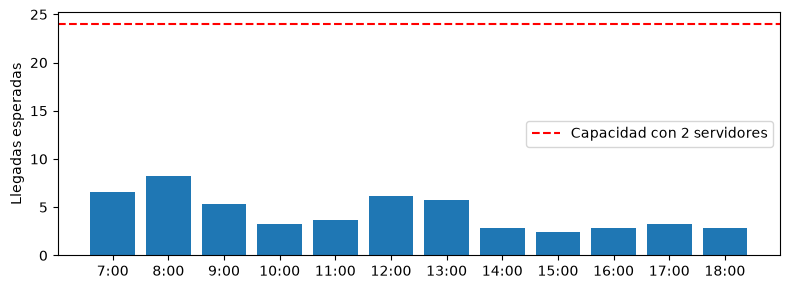

Visitas diarias esperadas = 53.3, pico por hora = 8.2


arrivals      52.033
served        51.067
balked         0.000
reneged        0.967
lost_share     0.018
mean_wait      0.057
dtype: float64

In [3]:
visitas_dia = p.demand_mature / qp.days_per_month
tasas = hourly_rates(visitas_dia, qp)
horas = [f"{7 + h}:00" for h in range(len(tasas))]

plt.figure(figsize=(8, 3))
plt.bar(horas, tasas)
plt.axhline(qp.servers * 60 / qp.service_mean, color="red", ls="--", label="Capacidad con 2 servidores")
plt.ylabel("Llegadas esperadas")
plt.legend()
plt.tight_layout()
plt.show()

rng = np.random.default_rng(4)
dias = pd.DataFrame([simulate_day(visitas_dia, qp, rng) for _ in range(30)])
print(f"Visitas diarias esperadas = {visitas_dia:.1f}, pico por hora = {tasas.max():.1f}")
dias.mean().round(3)

El pico de 8.2 llegadas por hora queda muy por debajo de la capacidad de 24. Aun así, por el azar de las llegadas se forman colas cortas. En 30 días simulados llegan 52.0 clientes por día, 0.97 se van por falta de paciencia y ninguno desiste al ver la cola, lo que equivale a 1.8 % de visitas perdidas.

## 4. Tabla de pérdida

Correr SimPy dentro de cada mes de miles de escenarios sería lento. Por eso se precalcula una tabla con la fracción de visitas perdidas para cada nivel de visitas diarias y número de servidores. Cada celda resume 60 días simulados, y el modelo integrado la consulta por interpolación.

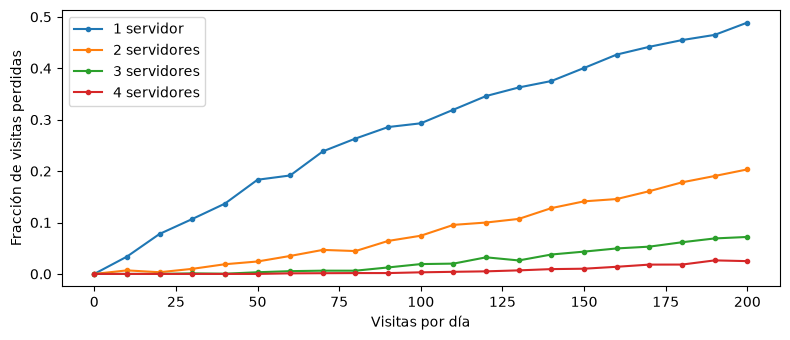

,1,2,3,4
daily_visits,,,,
20,0.078,0.003,0.000,0.000
40,0.137,0.019,0.000,0.000
60,0.192,0.035,0.005,0.001
80,0.263,0.044,0.006,0.002
100,0.293,0.074,0.019,0.003
150,0.401,0.141,0.043,0.010
200,0.489,0.203,0.072,0.025


In [4]:
malla = list(range(0, 201, 10))
tabla = loss_table(qp, malla, [1, 2, 3, 4], days=60, seed=5)

plt.figure(figsize=(8, 3.5))
for c in tabla.columns:
    plt.plot(tabla.index, tabla[c], marker="o", ms=3, label=f"{c} servidor{'es' if c > 1 else ''}")
plt.xlabel("Visitas por día")
plt.ylabel("Fracción de visitas perdidas")
plt.legend()
plt.tight_layout()
plt.show()
tabla.loc[[20, 40, 60, 80, 100, 150, 200]].round(3)

La pérdida crece con las visitas y baja con cada servidor adicional. Con 60 visitas por día se pierde 19.2 % con 1 servidor, 3.5 % con 2 y 0.5 % con 3. Con 200 visitas por día las pérdidas son de 48.9 %, 20.3 % y 7.2 %. Algunas curvas no son perfectamente crecientes por el ruido de la simulación.

## 5. Pérdida con la demanda esperada

Se aplica la tabla a la demanda del notebook 01, dividida entre 30 días.

In [5]:
diarias = demand_curve(p) / qp.days_per_month
resumen = {}
for c in [1, 2, 3]:
    perdida = loss_fraction(tabla, diarias, c)
    resumen[f"{c} servidor{'es' if c > 1 else ''}"] = {
        "Pérdida mes 1": perdida[0],
        "Pérdida mes 24": perdida[-1],
        "Visitas perdidas en 24 meses": (perdida * demand_curve(p)).sum(),
        "Margen perdido en 24 meses (Q)": (perdida * demand_curve(p)).sum() * p.margin,
    }
pd.DataFrame(resumen).round(3)

,1 servidor,2 servidores,3 servidores
Pérdida mes 1,0.093,0.007,0.001
Pérdida mes 24,0.188,0.031,0.005
Visitas perdidas en 24 meses,4835.326,643.872,70.639
Margen perdido en 24 meses (Q),145059.779,19316.168,2119.183


Con 2 servidores la pérdida pasa de 0.7 % en el mes 1 a 3.1 % en el mes 24. En 24 meses se pierden 644 visitas, equivalentes a Q19 316 de margen. Con 1 servidor se perderían Q145 060. Con 3 servidores la pérdida baja a Q2 119, pero un empleado más cuesta Q4 500 al mes, es decir Q108 000 en 24 meses.

## Conclusión

La cola convierte el exceso de visitas en ventas perdidas. Con la demanda esperada y 2 servidores la pérdida es pequeña, pero crece si la demanda sube. El siguiente notebook une las tres capas y agrega la incertidumbre con Monte Carlo.